# Chapter 3 Practice: Market Direction (messy, real-world data), answer key

**Data:**
- **S&P 500 index, daily OHLCV, 1999–2018**, downloaded from Yahoo Finance and bundled with the `arch` package (`pip install arch`).
- **VIX index, daily OHLC, 1990–today**, from the [datahub `finance-vix`](https://github.com/datasets/finance-vix) CSV on GitHub. VIX is the market's expectation of volatility over the next 30 days, which is why it's often called the "fear gauge".

**Why this is "messy" compared with `Smarket`:**
1. Two sources with **different calendars** have to be aligned.
2. There are **data-quality errors** in the raw files.
3. There are **no features and no label**. All you get is prices, and you have to build both yourself.
4. Prices are **non-stationary**, so they can't be used as features directly.
5. **Lookahead bias** is easy to introduce by accident.
6. Ordinary k-fold CV **leaks the future** into training.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rc("font", size=12)
plt.rc("axes", labelsize=12, titlesize=13)

## P1. Load both sources

In [2]:
from arch.data import sp500  # pip install arch

spx = sp500.load()
spx.head()

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
1999-01-04,1229.229980,1248.810059,1219.099976,1228.099976,1228.099976,877000000
1999-01-05,1228.099976,1246.109985,1228.099976,1244.780029,1244.780029,775000000
1999-01-06,1244.780029,1272.500000,1244.780029,1272.339966,1272.339966,986900000
1999-01-07,1272.339966,1272.339966,1257.680054,1269.729980,1269.729980,863000000
1999-01-08,1269.729980,1278.239990,1261.819946,1275.089966,1275.089966,937800000


In [3]:
vix_url = "https://raw.githubusercontent.com/datasets/finance-vix/main/data/vix-daily.csv"
vix_raw = pd.read_csv(vix_url, parse_dates=["DATE"], index_col="DATE")
vix_raw.tail()

,OPEN,HIGH,LOW,CLOSE
DATE,,,,
2026-09-16,16.91,18.94,16.40,17.71
2026-09-17,16.03,16.29,15.38,15.44
2026-09-18,15.07,15.63,14.80,14.81
2026-09-21,14.96,15.13,14.60,14.87
2026-09-22,14.64,14.95,14.19,14.21


## P2. Inspect: types, ranges, duplicates, calendars

In [4]:
print("SPX:", spx.index.min().date(), "->", spx.index.max().date(), spx.shape)
print("VIX:", vix_raw.index.min().date(), "->", vix_raw.index.max().date(), vix_raw.shape)
print("duplicate dates  SPX:", spx.index.duplicated().sum(), " VIX:", vix_raw.index.duplicated().sum())
print("missing values   SPX:", spx.isna().sum().sum(), " VIX:", vix_raw.isna().sum().sum())

SPX: 1999-01-04 -> 2018-12-31 (5031, 6)
VIX: 1990-01-02 -> 2026-09-22 (9278, 4)
duplicate dates  SPX: 0  VIX: 0
missing values   SPX: 0  VIX: 0


In [5]:
# Only look at the overlapping period
vix = vix_raw.loc[spx.index.min():spx.index.max()]

print("Dates in SPX but not VIX:", list(spx.index.difference(vix.index).date))
print("Dates in VIX but not SPX:", list(vix.index.difference(spx.index).date))

Dates in SPX but not VIX: [datetime.date(1999, 12, 31)]
Dates in VIX but not SPX: [datetime.date(2004, 6, 11)]


> **Why:** 2004-06-11 was a market holiday (President Reagan's funeral) but the VIX file still has a row for it, and the VIX file is missing 1999-12-31. We predict **S&P 500** moves, so the S&P 500 calendar is the master: keep every SPX day, and fill a missing VIX value with the previous day's value (that value was known at the time, so it doesn't leak).

In [6]:
# Sanity check: in every OHLC bar, Low <= Open <= High and Low <= Close <= High must hold
bad_vix = vix[(vix["OPEN"] < vix["LOW"]) | (vix["OPEN"] > vix["HIGH"])]
print(f"VIX rows where OPEN is outside [LOW, HIGH]: {len(bad_vix)}")
bad_vix.head(10)

VIX rows where OPEN is outside [LOW, HIGH]: 5


,OPEN,HIGH,LOW,CLOSE
DATE,,,,
1999-04-01,22.03,22.87,22.06,22.06
2002-09-11,35.98,34.81,33.72,34.81
2004-10-26,19.54,16.87,15.97,16.39
2004-11-08,2.58,14.48,13.68,13.80
2006-02-08,41.60,13.61,12.76,12.83


In [7]:
bad_spx = spx[(spx["Open"] < spx["Low"]) | (spx["Open"] > spx["High"]) |
              (spx["Close"] < spx["Low"]) | (spx["Close"] > spx["High"])]
print(f"SPX rows breaking OHLC rules: {len(bad_spx)}")
print(f"SPX rows with zero volume:    {(spx['Volume'] == 0).sum()}")
print(f"Close != Adj Close on {(spx['Close'] != spx['Adj Close']).sum()} rows")

SPX rows breaking OHLC rules: 0
SPX rows with zero volume:    0
Close != Adj Close on 0 rows


> **Why:** Five VIX rows have an OPEN outside the day's range (e.g. 2.58 on 2004-11-08, when VIX was near 14), which is a typical data-entry error. We only need the VIX **close**, which is what quants usually use, so we ignore OPEN/HIGH/LOW. That avoids both dropping S&P 500 rows and inventing corrected values. `Close == Adj Close` everywhere because a price index pays no dividends.

In [8]:
# Calendar gaps: how many calendar days between consecutive trading days?
gaps = spx.index.to_series().diff().dt.days
print(gaps.value_counts().sort_index())
gaps[gaps >= 5]

Date
1.0    3940
2.0      47
3.0     910
4.0     130
5.0       2
7.0       1
Name: count, dtype: int64


Date
2001-09-17    7.0
2007-01-03    5.0
2012-10-31    5.0
Name: Date, dtype: float64

> **Why:** The market was closed after 9/11, for President Ford's national day of mourning, and for Hurricane Sandy, so those returns cover 5–7 calendar days. We keep them because they really happened, but some 'daily' returns span longer periods (every Monday does too).

## P3. Align the two sources on the S&P 500 calendar

In [9]:
df = spx.join(vix[["CLOSE"]].rename(columns={"CLOSE": "VIX"}), how="left")
print("Missing VIX after join:", df["VIX"].isna().sum())
df["VIX"] = df["VIX"].ffill(limit=1)  # carry forward at most 1 day
print("Missing VIX after ffill:", df["VIX"].isna().sum())
df.head()

Missing VIX after join: 1
Missing VIX after ffill: 0


,Open,High,Low,Close,Adj Close,Volume,VIX
Date,,,,,,,
1999-01-04,1229.229980,1248.810059,1219.099976,1228.099976,1228.099976,877000000,26.17
1999-01-05,1228.099976,1246.109985,1228.099976,1244.780029,1244.780029,775000000,24.46
1999-01-06,1244.780029,1272.500000,1244.780029,1272.339966,1272.339966,986900000,23.34
1999-01-07,1272.339966,1272.339966,1257.680054,1269.729980,1269.729980,863000000,24.37
1999-01-08,1269.729980,1278.239990,1261.819946,1275.089966,1275.089966,937800000,23.28


## P4. Prices are non-stationary, so use returns

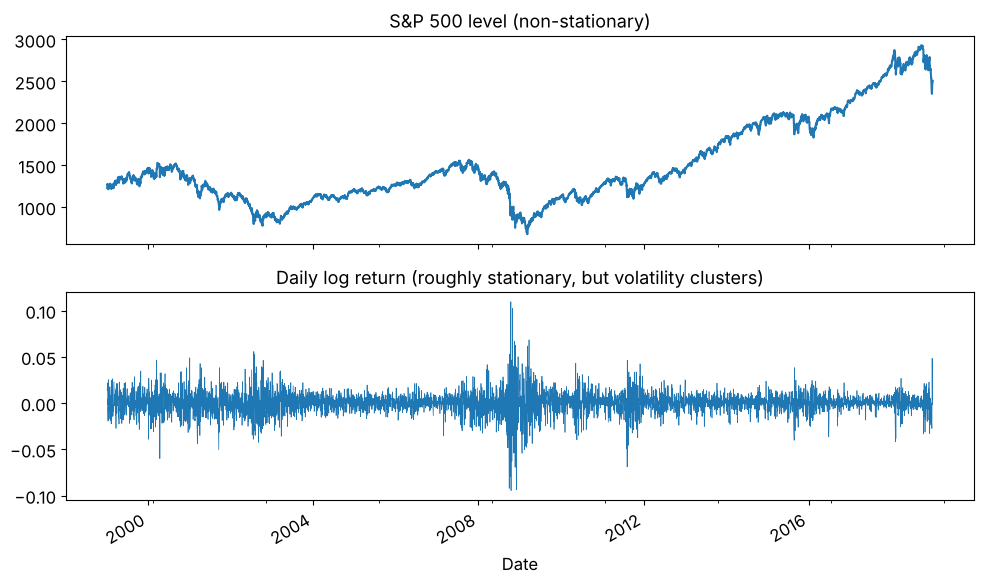

In [10]:
log_ret = np.log(df["Adj Close"]).diff()

fig, axs = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
df["Adj Close"].plot(ax=axs[0], title="S&P 500 level (non-stationary)")
log_ret.plot(ax=axs[1], title="Daily log return (roughly stationary, but volatility clusters)", linewidth=0.5)
plt.tight_layout()
plt.show()

> **Why:** Trees can't extrapolate. Every test-period price is above the training range, so they all land in the same 'highest price' leaf. Linear models face a similar problem: the meaning of the feature drifts over time. Returns and ratios (like price / moving average) keep roughly the same scale over decades.

## P5. Feature engineering: use only information known at the close of day *t*

In [11]:
px = df["Adj Close"]
feat = pd.DataFrame(index=df.index)

for k in range(5):                                 # today's return and the 4 before it
    feat[f"ret_{k}"] = log_ret.shift(k)
feat["mom_5"] = np.log(px / px.shift(5))           # 1-week momentum
feat["mom_20"] = np.log(px / px.shift(20))         # 1-month momentum
feat["vol_20"] = log_ret.rolling(20).std()         # realized volatility over the last month
feat["range"] = (df["High"] - df["Low"]) / df["Close"]  # intraday range
feat["dist_ma50"] = px / px.rolling(50).mean() - 1      # distance from the 50-day moving average
feat["logvol_chg"] = np.log(df["Volume"]).diff()        # change in trading volume
feat["vix"] = df["VIX"]                                 # implied volatility level
feat["vix_chg"] = np.log(df["VIX"]).diff()              # change in implied volatility

feat.describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
ret_0,0.000142,0.012038,-0.094695,0.109572
ret_1,0.000140,0.012039,-0.094695,0.109572
ret_2,0.000140,0.012040,-0.094695,0.109572
ret_3,0.000139,0.012041,-0.094695,0.109572
ret_4,0.000129,0.012023,-0.094695,0.109572
mom_5,0.000667,0.024608,-0.202607,0.174887
mom_20,0.002884,0.045515,-0.330730,0.211030
vol_20,0.010295,0.006362,0.002069,0.053665
range,0.013379,0.009971,0.001456,0.107382
dist_ma50,0.003985,0.039432,-0.259172,0.143027


## P6. Build the target: *tomorrow's* return

In [12]:
next_ret = log_ret.shift(-1)   # return from close t to close t+1
data = feat.assign(next_ret=next_ret)
data[["ret_0", "next_ret"]].head(3)

,ret_0,next_ret
Date,,
1999-01-04,NaN,0.013491
1999-01-05,0.013491,0.021899
1999-01-06,0.021899,-0.002053


> **Why:** `shift(-1)` pulls tomorrow's value up into today's row, so every row pairs today's features with tomorrow's outcome. Getting the shift wrong is the classic lookahead bug: the target ends up equal to a feature (or the features include the future), and accuracy jumps toward 100%. Accuracy far above ~55% on daily direction should make you suspect a bug.

In [13]:
# Leakage smoke test: no feature should be strongly correlated with next-day return.
# A |corr| above ~0.2 on daily returns almost always means a lookahead bug.
corr = data.corr()["next_ret"].drop("next_ret").sort_values()
print(corr.round(3))
assert corr.abs().max() < 0.2, "Suspiciously strong correlation, so check for leakage!"

mom_5        -0.080
ret_0        -0.070
ret_1        -0.047
ret_4        -0.046
dist_ma50    -0.045
mom_20       -0.041
ret_3        -0.013
logvol_chg   -0.011
vol_20       -0.006
ret_2         0.014
vix           0.026
range         0.031
vix_chg       0.037
Name: next_ret, dtype: float64


## P7. Drop warm-up rows and the last row

In [14]:
print("Rows with NaN before dropna:", data.isna().any(axis=1).sum())
data = data.dropna()
print("Rows after dropna:", len(data), "|", data.index.min().date(), "->", data.index.max().date())

Rows with NaN before dropna: 50
Rows after dropna: 4981 | 1999-03-16 -> 2018-12-28


> **Why:** The first ~50 rows have NaNs because rolling windows (like the 50-day MA) need history, and the last row has no tomorrow. Filling `next_ret` with 0 would invent a 'flat' day that never happened.

## P8. Chronological train/test split

In [15]:
train = data.loc[:"2014"]
test = data.loc["2015":]

feature_cols = [c for c in data.columns if c != "next_ret"]
X_train, X_test = train[feature_cols], test[feature_cols]

y_train_up = (train["next_ret"] > 0).to_numpy()
y_test_up = (test["next_ret"] > 0).to_numpy()

print(f"train: {len(X_train)} days ({train.index.min().date()} -> {train.index.max().date()}), Up rate {y_train_up.mean():.3f}")
print(f"test:  {len(X_test)} days ({test.index.min().date()} -> {test.index.max().date()}), Up rate {y_test_up.mean():.3f}")

train: 3976 days (1999-03-16 -> 2014-12-31), Up rate 0.534
test:  1005 days (2015-01-02 -> 2018-12-28), Up rate 0.522


> **Why:** The default `shuffle=True` would put days from 2018 in training and days from 2001 in test, so the model would learn from the future. Overlapping rolling features also mean neighbouring days share information. Always train on the past and test on the future.

## P9. Cross-validation that respects time

In [16]:
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5)
for i, (tr_idx, va_idx) in enumerate(tscv.split(X_train)):
    print(f"fold {i}: train {X_train.index[tr_idx[0]].date()}..{X_train.index[tr_idx[-1]].date()}"
          f"  ->  validate {X_train.index[va_idx[0]].date()}..{X_train.index[va_idx[-1]].date()}")

fold 0: train 1999-03-16..2001-11-06  ->  validate 2001-11-07..2004-06-25
fold 1: train 1999-03-16..2004-06-25  ->  validate 2004-06-28..2007-02-12
fold 2: train 1999-03-16..2007-02-12  ->  validate 2007-02-13..2009-09-28
fold 3: train 1999-03-16..2009-09-28  ->  validate 2009-09-29..2012-05-14
fold 4: train 1999-03-16..2012-05-14  ->  validate 2012-05-15..2014-12-31


> **Why:** `cross_val_predict` needs every sample to be in exactly one validation fold. `TimeSeriesSplit` never validates the first block, because there is no past data to train on before it. The helper below collects out-of-fold predictions only for the rows that are validated, and returns their positions so you can line up `y`.

In [17]:
from sklearn.base import clone

def oof_predict(model, X, y, cv, method="predict"):
    """Out-of-fold predictions for CV splitters that don't cover every row (e.g. TimeSeriesSplit).

    Returns (idx, preds): the row positions that were validated, and the predictions for them.
    Compare preds against y[idx].
    """
    y = np.asarray(y)
    all_idx, all_preds = [], []
    for tr_idx, va_idx in cv.split(X):
        fitted = clone(model).fit(X.iloc[tr_idx], y[tr_idx])
        all_preds.append(getattr(fitted, method)(X.iloc[va_idx]))
        all_idx.append(va_idx)
    return np.concatenate(all_idx), np.concatenate(all_preds)

## P10. Scaling: inside a `Pipeline`, never on the full dataset

SGD, SVC and KNN need scaled features. Fitting `StandardScaler` on all of `X_train` before CV would leak the validation folds' mean and std into training, so wrap the scaler with the model instead:

```python
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier

sgd_clf = make_pipeline(StandardScaler(), SGDClassifier(random_state=42))
```

**✅ Data is ready.** You now have `X_train`, `X_test`, `y_train_up`, `y_test_up`, `tscv`, `oof_predict`, plus `train["next_ret"]` / `test["next_ret"]` for building other labels.

---
# Part 2: Chapter 3 steps on the prepared data

## 1. Binary classifier + dummy baseline
*(Book: "Training a Binary Classifier", "Measuring Accuracy Using Cross-Validation")*

In [18]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score

sgd_clf = make_pipeline(StandardScaler(), SGDClassifier(random_state=42))
forest_clf = RandomForestClassifier(n_estimators=200, min_samples_leaf=20,
                                    random_state=42, n_jobs=-1)

for name, model in [("dummy", DummyClassifier()), ("SGD", sgd_clf), ("RF", forest_clf)]:
    acc = cross_val_score(model, X_train, y_train_up, cv=tscv, scoring="accuracy")
    print(f"{name:6s} accuracy per fold {acc.round(3)}  mean={acc.mean():.3f}")

dummy  accuracy per fold [0.495 0.437 0.526 0.562 0.562]  mean=0.516


SGD    accuracy per fold [0.465 0.515 0.464 0.502 0.563]  mean=0.502


RF     accuracy per fold [0.47  0.489 0.514 0.489 0.53 ]  mean=0.498


**Lesson:** the dummy's accuracy swings from fold to fold (≈0.44–0.56) because the share of Up days changes with the market regime: 2008 vs 2013, for example. No model consistently beats the dummy, and **the variation between folds is bigger than any edge.** Always look at the per-fold numbers, not only the mean.

`min_samples_leaf=20` matters for the forest. With noisy targets, fully grown trees memorize noise.

## 2. Confusion matrix, precision, recall
*(Book: `cross_val_predict` + `confusion_matrix`; here we use `oof_predict` because of `TimeSeriesSplit`)*

In [19]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

idx, y_pred = oof_predict(sgd_clf, X_train, y_train_up, tscv)
y_true = y_train_up[idx]
print(confusion_matrix(y_true, y_pred))
print(f"precision {precision_score(y_true, y_pred):.3f} | recall {recall_score(y_true, y_pred):.3f} "
      f"| F1 {f1_score(y_true, y_pred):.3f} | Up base rate {y_true.mean():.3f}")

[[730 781]
 [868 931]]
precision 0.544 | recall 0.518 | F1 0.530 | Up base rate 0.544


## 3. Precision/recall trade-off

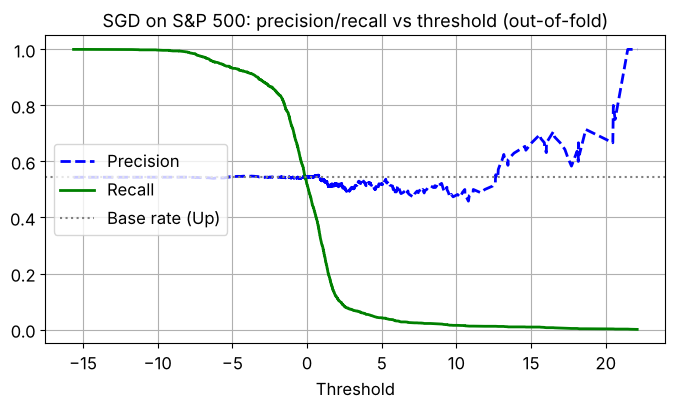

In [20]:
from sklearn.metrics import precision_recall_curve

idx, y_scores = oof_predict(sgd_clf, X_train, y_train_up, tscv, method="decision_function")
y_true = y_train_up[idx]
precisions, recalls, thresholds = precision_recall_curve(y_true, y_scores)

plt.figure(figsize=(8, 4))
plt.plot(thresholds, precisions[:-1], "b--", label="Precision", linewidth=2)
plt.plot(thresholds, recalls[:-1], "g-", label="Recall", linewidth=2)
plt.axhline(y_true.mean(), color="gray", linestyle=":", label="Base rate (Up)")
plt.xlabel("Threshold")
plt.grid()
plt.legend(loc="center left")
plt.title("SGD on S&P 500: precision/recall vs threshold (out-of-fold)")
plt.show()

## 4. ROC curve and AUC: SGD vs Random Forest

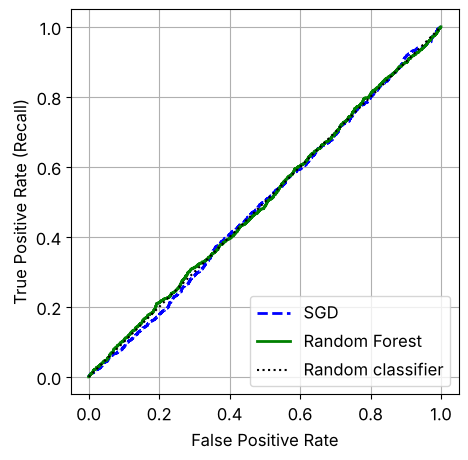

OOF ROC AUC  SGD: 0.496
OOF ROC AUC  RF:  0.501


In [21]:
from sklearn.metrics import roc_curve, roc_auc_score

idx, y_proba_rf = oof_predict(forest_clf, X_train, y_train_up, tscv, method="predict_proba")
y_scores_rf = y_proba_rf[:, 1]

fpr, tpr, _ = roc_curve(y_true, y_scores)
fpr_f, tpr_f, _ = roc_curve(y_true, y_scores_rf)
plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, "b--", linewidth=2, label="SGD")
plt.plot(fpr_f, tpr_f, "g-", linewidth=2, label="Random Forest")
plt.plot([0, 1], [0, 1], "k:", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.grid()
plt.legend(loc="lower right")
plt.show()

print(f"OOF ROC AUC  SGD: {roc_auc_score(y_true, y_scores):.3f}")
print(f"OOF ROC AUC  RF:  {roc_auc_score(y_true, y_scores_rf):.3f}")

## 5. Multiclass: Down / Flat / Up (training-set terciles of tomorrow's return)

In [22]:
from sklearn.svm import SVC

q1, q2 = train["next_ret"].quantile([1/3, 2/3])
labels = ["Down", "Flat", "Up"]
to_3class = lambda r: pd.cut(r, [-np.inf, q1, q2, np.inf], labels=labels).astype(str).to_numpy()
y_train_3 = to_3class(train["next_ret"])
y_test_3 = to_3class(test["next_ret"])
print(f"cut points: {q1:.4f}, {q2:.4f} (log returns)")

svm_clf = make_pipeline(StandardScaler(), SVC(random_state=42))
sgd3 = make_pipeline(StandardScaler(), SGDClassifier(random_state=42))
for name, model in [("dummy", DummyClassifier()), ("SGD", sgd3), ("SVC", svm_clf)]:
    acc = cross_val_score(model, X_train, y_train_3, cv=tscv, scoring="accuracy")
    print(f"{name:6s} {acc.round(3)}  mean={acc.mean():.3f}")

cut points: -0.0030, 0.0040 (log returns)
dummy  [0.378 0.281 0.364 0.316 0.257]  mean=0.319


SGD    [0.358 0.325 0.426 0.369 0.447]  mean=0.385


SVC    [0.372 0.391 0.423 0.375 0.455]  mean=0.403


## 6. Error analysis

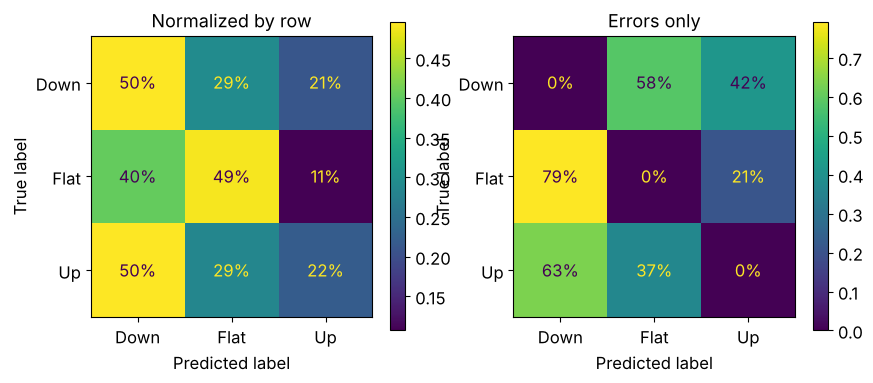

In [23]:
from sklearn.metrics import ConfusionMatrixDisplay

idx3, y_pred3 = oof_predict(svm_clf, X_train, y_train_3, tscv)
y_true3 = y_train_3[idx3]
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_true3, y_pred3, ax=axs[0], labels=labels,
                                        normalize="true", values_format=".0%")
axs[0].set_title("Normalized by row")
ConfusionMatrixDisplay.from_predictions(y_true3, y_pred3, ax=axs[1], labels=labels,
                                        sample_weight=(y_pred3 != y_true3),
                                        normalize="true", values_format=".0%")
axs[1].set_title("Errors only")
plt.show()

**What to notice:** look at the **Flat** row and column. Tomorrow's move is usually small when volatility is low, and volatility is the one thing the features *do* capture: VIX and `vol_20`. So any skill the model has tends to come from separating Flat from {Down, Up}, not Down from Up. That leads straight into the multilabel section.

## 7. Multilabel: [Up, Big move]
*(Book: `KNeighborsClassifier` on `y_multilabel`, then `ClassifierChain`)*

In [24]:
from sklearn.neighbors import KNeighborsClassifier

y_train_big = (train["next_ret"].abs() > 0.01).to_numpy()  # |move| > 1%
y_test_big = (test["next_ret"].abs() > 0.01).to_numpy()
y_multilabel = np.c_[y_train_up, y_train_big]
print(f"BigMove base rate: train {y_train_big.mean():.3f}, test {y_test_big.mean():.3f}")

knn_clf = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=25))
idx_ml, y_pred_ml = oof_predict(knn_clf, X_train, y_multilabel, tscv)
y_true_ml = y_multilabel[idx_ml]
print("macro F1:", round(f1_score(y_true_ml, y_pred_ml, average="macro"), 3))
print("F1 per label [Up, BigMove]:", f1_score(y_true_ml, y_pred_ml, average=None).round(3))

BigMove base rate: train 0.302, test 0.189


macro F1: 0.449
F1 per label [Up, BigMove]: [0.537 0.361]


In [25]:
for name, y_lbl in [("Up", y_train_up), ("BigMove", y_train_big)]:
    idx_l, p = oof_predict(forest_clf, X_train, y_lbl, tscv, method="predict_proba")
    print(f"RF OOF ROC AUC {name:8s}: {roc_auc_score(y_lbl[idx_l], p[:, 1]):.3f}")

RF OOF ROC AUC Up      : 0.501


RF OOF ROC AUC BigMove : 0.755


In [26]:
from sklearn.multioutput import ClassifierChain

chain_clf = ClassifierChain(make_pipeline(StandardScaler(), SVC()), cv=3, random_state=42)
chain_clf.fit(X_train.iloc[:2000], y_multilabel[:2000])  # the book also trains on a subset to save time
chain_clf.predict(X_train.iloc[[-1]])

array([[1., 0.]])

In [27]:
# Which features drive BigMove?
rf_big = clone(forest_clf).fit(X_train, y_train_big)
pd.Series(rf_big.feature_importances_, index=feature_cols).sort_values(ascending=False).round(3)

vix           0.210
vol_20        0.163
dist_ma50     0.103
mom_20        0.097
range         0.071
mom_5         0.060
ret_1         0.057
ret_0         0.050
ret_3         0.044
ret_2         0.042
ret_4         0.038
logvol_chg    0.034
vix_chg       0.032
dtype: float64

**Lesson:** VIX and 20-day realized volatility dominate. **Volatility clusters, but direction doesn't.** This is one of the most robust facts in empirical finance, and you just found it with the Chapter 3 toolkit.

## 8. Final evaluation on 2015–2018 (touch the test set once)

In [28]:
results = {}
for name, model in [("dummy (always Up)", DummyClassifier()), ("SGD", sgd_clf), ("RF", forest_clf)]:
    fitted = clone(model).fit(X_train, y_train_up)
    acc = (fitted.predict(X_test) == y_test_up).mean()
    results[name] = acc
    print(f"Up      | {name:18s} test accuracy = {acc:.3f}")

rf_up = clone(forest_clf).fit(X_train, y_train_up)
print(f"Up      | RF test ROC AUC = {roc_auc_score(y_test_up, rf_up.predict_proba(X_test)[:, 1]):.3f}")
print(f"BigMove | RF test ROC AUC = {roc_auc_score(y_test_big, rf_big.predict_proba(X_test)[:, 1]):.3f}")

se = np.sqrt(0.25 / len(y_test_up))
print(f"\n±2 SE band for a coin flip on {len(y_test_up)} days: {0.5 - 2*se:.3f}–{0.5 + 2*se:.3f}")

Up      | dummy (always Up)  test accuracy = 0.522
Up      | SGD                test accuracy = 0.520


Up      | RF                 test accuracy = 0.512


Up      | RF test ROC AUC = 0.516
BigMove | RF test ROC AUC = 0.827

±2 SE band for a coin flip on 1005 days: 0.468–0.532


## 9. Takeaways and what a "good enough" answer looks like

| Check | Good-enough range |
|---|---|
| Calendars aligned on the SPX dates; VIX OPEN anomaly noticed; only the VIX close used | required |
| Features built from returns/ratios, not price levels | required |
| Target built with `shift(-1)`; no feature uses data from *t+1* | required |
| Chronological split + `TimeSeriesSplit` (not shuffled k-fold) | required |
| Scaling inside a `Pipeline` | required |
| Dummy baseline reported **per fold** | required |
| Up: accuracy (CV / test) | ≈ the dummy's, ~0.45–0.56 depending on the period |
| Up: ROC AUC | ~0.47–0.53 |
| 3-class accuracy | ~0.35–0.42 vs a dummy at ~0.32 |
| BigMove: ROC AUC | ~0.70–0.85 (clearly above Up) |
| Conclusion | "direction ≈ unpredictable; volatility/magnitude is predictable" |

If your **Up** accuracy is well above ~0.56, suspect leakage first (go back to P6/P8) before you celebrate.

**Where this goes next in the book:** Chapter 4 adds logistic regression and regularization. Chapter 6 tunes ensembles. Chapter 13 covers sequence models that read the raw return series directly.